# Lab 2.4 — REINFORCE: Monte Carlo Policy Gradient with PyTorch
## 🧑‍🏫 INSTRUCTOR SOLUTION
**Course:** AI Agents · **Unit:** UC2 2.4 Policy Gradient Methods · **Environment:** `CartPole-v1`

This notebook is the reference solution of the student lab guide. It has the same cells, with every `TODO` completed, plus:
- a suggested **grading rubric** (below),
- **teaching notes** (🧑‍🏫) where students usually get stuck,
- an **answer key** for the questions of Part 8.

> Expected behaviour with the default hyperparameters (Adam, lr = 1e-3, γ = 0.99, normalized returns, 1000 episodes): the 100-episode average climbs from ~20 to several hundred and usually touches the 500 cap after 600–800 episodes, with visible drops afterwards (high variance, slide 21). Training takes about 3–8 minutes on a laptop CPU. Exact numbers depend on the seed and the library versions.

### Suggested grading rubric (100 pts)
| Item | Points | What to look for |
|---|---|---|
| TODO 1 – explore the environment | 5 | Correct spaces; random-policy episode length (~10–40) |
| TODO 2–4 – policy network | 20 | 4→64→64→64→2, ReLU, softmax on `dim=-1`; `act` samples with `Categorical` and returns `log_prob` **with** gradient |
| TODO 5 – returns | 15 | Backward recursion; check matches slide 17; normalization uses `mean`/`std` |
| TODO 6 – loss | 10 | Minus sign; `torch.stack`; sum over time steps |
| TODO 7–9 – REINFORCE loop | 25 | Full episode before update; `zero_grad` → `backward` → `step` once per episode |
| TODO 10 – evaluation | 5 | `torch.no_grad()`, greedy = argmax |
| TODO 11 – experiments | 10 | At least 3 configurations, plotted and commented |
| Part 8 – questions | 10 | See answer key |
| *Optional TODO 12* | +5 bonus | γᵗ factor implemented and compared |

## Part 0 — Setup
If you work in Google Colab or a fresh environment, uncomment and run the install line first.

In [ ]:
# %pip install -q gymnasium torch matplotlib

In [1]:
import random
from collections import deque

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions import Categorical

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed()
device = torch.device("cpu")   # a tiny network on CartPole is faster on CPU than on GPU
print("PyTorch", torch.__version__, "| Gymnasium", gym.__version__)

PyTorch 2.7.1+cu126 | Gymnasium 1.1.1


## Part 1 — Meet CartPole (slide 6)
A pole is attached to a cart moving on a track. The agent pushes the cart **left (0)** or **right (1)**.
- **State** $s_t$ (4 numbers): cart position, cart velocity, pole angle, pole angular velocity.
- **Reward:** +1 for every step the pole stays up.
- **Episode ends** when the pole tilts more than 12°, the cart leaves the track, or after **500 steps** (maximum return = 500).

### TODO 1
1. Create the environment `CartPole-v1` and store it in `env`.
2. Print its `observation_space` and `action_space`, and store the sizes in `state_size` and `action_size`.
3. Play **one** episode with a **random** policy (`env.action_space.sample()`) and print its length.

In [2]:
# ---------------------------- TODO 1 ----------------------------
env = gym.make("CartPole-v1")
print("Observation space:", env.observation_space)
print("Action space     :", env.action_space)

state_size = env.observation_space.shape[0]   # 4
action_size = env.action_space.n              # 2

state, info = env.reset(seed=SEED)
env.action_space.seed(SEED)
steps, done = 0, False
while not done:
    state, reward, terminated, truncated, info = env.step(env.action_space.sample())
    steps += 1
    done = terminated or truncated
print(f"Random policy survived {steps} steps")
# ----------------------------------------------------------------

Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Action space     : Discrete(2)
Random policy survived 30 steps


In [3]:
# ✔ Check Part 1
assert state_size == 4 and action_size == 2, "CartPole has 4 state variables and 2 actions"
print("✅ Part 1 OK — a random agent is our baseline: it usually survives only 10–40 steps.")

✅ Part 1 OK — a random agent is our baseline: it usually survives only 10–40 steps.


## Part 2 — The policy network (slides 6 and 20)
Our policy $\pi_\theta(a \mid s)$ is a neural network with parameters $\theta$. It receives the state and outputs **one probability per action** (they sum to 1).

Architecture (slide 20):

| Layer | Size | Activation |
|---|---|---|
| Input | `state_size` = 4 | – |
| Hidden 1 | 64 | ReLU |
| Hidden 2 | 64 | ReLU |
| Hidden 3 | 64 | ReLU |
| Output | `action_size` = 2 | **Softmax** |

To **act**, we do not pick the most probable action: we **sample** from the distribution (slide 18 — this is where exploration comes from) and we keep $\log \pi_\theta(a_t \mid s_t)$ because the update rule needs it.

> 🧑‍🏫 **Common mistakes:** (1) softmax over `dim=0` (the batch) instead of the actions; (2) calling `act` inside `torch.no_grad()` or using `.detach()`/`.item()` on the log-prob, which silently kills learning — the loss then has no gradient and `backward()` fails or nothing changes; (3) returning `argmax` instead of a sample, which removes exploration.

In [4]:
class PolicyNetwork(nn.Module):
    def __init__(self, state_size, action_size, hidden_size=64):
        super().__init__()
        # ---------------------------- TODO 2 ----------------------------
        self.fc1 = nn.Linear(state_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.fc3 = nn.Linear(hidden_size, hidden_size)
        self.out = nn.Linear(hidden_size, action_size)
        # ----------------------------------------------------------------

    def forward(self, x):
        # ---------------------------- TODO 3 ----------------------------
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        return F.softmax(self.out(x), dim=-1)
        # ----------------------------------------------------------------

    def act(self, state):
        # ---------------------------- TODO 4 ----------------------------
        state = torch.as_tensor(state, dtype=torch.float32, device=device).unsqueeze(0)
        probs = self.forward(state)            # shape (1, action_size)
        dist = Categorical(probs)
        action = dist.sample()                 # shape (1,)
        return action.item(), dist.log_prob(action).squeeze()
        # ----------------------------------------------------------------

In [5]:
# ✔ Check Part 2
set_seed()
_policy = PolicyNetwork(4, 2).to(device)
_p = _policy(torch.randn(5, 4))
assert _p.shape == (5, 2), f"forward must return (batch, 2), got {tuple(_p.shape)}"
assert torch.allclose(_p.sum(dim=1), torch.ones(5)), "each row of probabilities must sum to 1"
_n_params = sum(p.numel() for p in _policy.parameters())
assert _n_params == 8770, f"expected 8770 parameters for 4-64-64-64-2, got {_n_params}"
_a, _lp = _policy.act(np.zeros(4, dtype=np.float32))
assert isinstance(_a, int) and _a in (0, 1), "act must return the action as a Python int"
assert torch.is_tensor(_lp) and _lp.dim() == 0, "log_prob must be a 0-dim tensor (use .squeeze())"
assert _lp.requires_grad, "log_prob lost its gradient — do not use no_grad/detach/item in act()"
print(f"✅ Part 2 OK — {_n_params} parameters; π(·|s) for a random state: {_p[0].detach().numpy().round(3)}")

✅ Part 2 OK — 8770 parameters; π(·|s) for a random state: [0.49 0.51]


## Part 3 — Discounted returns $G_t$ (slide 17)
Line 4 of the algorithm computes, for **every** time step, the discounted sum of the rewards that came **after** it:
$$G_t = \sum_{k=t}^{T-1} \gamma^{\,k-t}\, r_k$$
Computing this sum separately for each $t$ is $O(T^2)$. Instead, go **backwards** with the recursion
$$G_{T-1} = r_{T-1}, \qquad G_t = r_t + \gamma\, G_{t+1}.$$

**Normalization.** In practice we often standardize the returns of the episode, $\hat G_t = (G_t - \text{mean}) / (\text{std} + 10^{-9})$. It keeps the step size stable and acts like a simple baseline (slide 21).

### TODO 5
Implement `compute_returns(rewards, gamma, normalize=False)` returning a `float32` tensor with one $G_t$ per step.

In [6]:
def compute_returns(rewards, gamma, normalize=False):
    # ---------------------------- TODO 5 ----------------------------
    returns = deque()
    G = 0.0
    for r in reversed(rewards):          # backward pass: G_t = r_t + γ G_{t+1}
        G = r + gamma * G
        returns.appendleft(G)
    returns = torch.tensor(list(returns), dtype=torch.float32, device=device)
    if normalize and len(returns) > 1:
        returns = (returns - returns.mean()) / (returns.std() + 1e-9)
    return returns
    # ----------------------------------------------------------------

In [7]:
# ✔ Check Part 3 — the worked example of slide 17: 5 steps, reward +1, γ = 0.9
_G = compute_returns([1.0] * 5, gamma=0.9)
print("G_t =", _G.numpy().round(2))
assert torch.allclose(_G, torch.tensor([4.0951, 3.439, 2.71, 1.9, 1.0]), atol=1e-3), "returns do not match slide 17"
_Gn = compute_returns([1.0] * 5, gamma=0.9, normalize=True)
assert abs(_Gn.mean().item()) < 1e-5 and abs(_Gn.std().item() - 1) < 1e-4, "normalized returns need mean 0 and std 1"
assert torch.allclose(compute_returns([0, 0, 1, -1], gamma=0.5), torch.tensor([0.125, 0.25, 0.5, -1.0])), "check a reward sequence that is not constant"
print("✅ Part 3 OK — early actions get credit for everything that followed them.")

G_t = [4.1  3.44 2.71 1.9  1.  ]
✅ Part 3 OK — early actions get credit for everything that followed them.


## Part 4 — The REINFORCE loss (slide 19)
The update of slide 16 is a gradient **ascent** step: $\theta \leftarrow \theta + \alpha\, G_t\, \nabla_\theta \log \pi_\theta(a_t \mid s_t)$.

PyTorch optimizers **minimize**, so we give them the negative of the quantity we want to maximize, summed over the episode:
$$L(\theta) = -\sum_{t=0}^{T-1} \log \pi_\theta(a_t \mid s_t)\; G_t$$
Calling `loss.backward()` then computes exactly $-\hat g$, and `optimizer.step()` moves $\theta$ uphill on $J(\theta)$.

### TODO 6
Implement `reinforce_loss(log_probs, returns)`.
- `log_probs`: Python **list** of 0-dim tensors (one per step, from `policy.act`).
- `returns`: tensor of shape `(T,)` from `compute_returns`.

> 💡 `torch.stack(list_of_tensors)` turns the list into a tensor of shape `(T,)`.

In [8]:
def reinforce_loss(log_probs, returns):
    # ---------------------------- TODO 6 ----------------------------
    return -(torch.stack(log_probs) * returns).sum()
    # ----------------------------------------------------------------

In [9]:
# ✔ Check Part 4
_lp = [torch.tensor(np.log(0.5), requires_grad=True), torch.tensor(np.log(0.25), requires_grad=True)]
_loss = reinforce_loss(_lp, torch.tensor([1.0, 2.0]))
assert _loss.dim() == 0, "the loss must be a scalar"
assert abs(_loss.item() - 3.4657) < 1e-3, f"expected 3.4657, got {_loss.item():.4f} — check the minus sign"
_loss.backward()
assert _lp[1].grad.item() == -2.0, "∂L/∂log π(a_t|s_t) should be −G_t"
print("✅ Part 4 OK — ∂L/∂log π = −G_t: minimizing L raises the log-probability of actions with high return.")

✅ Part 4 OK — ∂L/∂log π = −G_t: minimizing L raises the log-probability of actions with high return.


## Part 5 — The REINFORCE algorithm (slide 16)
Now put everything together. For each of the `n_episodes` iterations (line 1):

| Pseudocode line | What to do here |
|---|---|
| **2** — generate an episode following $\pi_\theta$ | `TODO 7`: reset the env, then loop: `policy.act(state)` → `env.step(action)`; store `log_prob` and `reward`; stop when `terminated or truncated` (or after `max_t` steps) |
| **4** — compute $G_t$ for all $t$ | `TODO 8`: call `compute_returns` |
| **5** — update $\theta$ | `TODO 9`: compute the loss, then `optimizer.zero_grad()`, `loss.backward()`, `optimizer.step()` |

Notice that the update happens **once the episode is over** — that is what makes it Monte Carlo — and that the episode is then thrown away (on-policy).

> 🧑‍🏫 **Teaching notes.** The pseudocode updates θ inside the `for t` loop (one step per time step). Doing one step with the **sum** over t is the standard implementation and is equivalent to a single gradient step on the whole episode; it is also much faster. A frequent bug is forgetting `optimizer.zero_grad()`: gradients then accumulate across episodes and training diverges. Another is updating inside the step loop with a partial episode, which is no longer Monte Carlo.

In [10]:
def reinforce(env, policy, optimizer, n_episodes=1000, gamma=0.99, max_t=500,
              normalize=True, print_every=100):
    scores = []                          # return of every episode
    scores_window = deque(maxlen=100)    # last 100 returns, for the running average

    for i_episode in range(1, n_episodes + 1):
        # ---------------------------- TODO 7 ----------------------------
        log_probs, rewards = [], []
        state, _ = env.reset()
        for t in range(max_t):
            action, log_prob = policy.act(state)
            state, reward, terminated, truncated, _ = env.step(action)
            log_probs.append(log_prob)
            rewards.append(reward)
            if terminated or truncated:
                break
        # ----------------------------------------------------------------

        episode_return = sum(rewards)
        scores.append(episode_return)
        scores_window.append(episode_return)

        # ---------------------------- TODO 8 ----------------------------
        returns = compute_returns(rewards, gamma, normalize)
        # ----------------------------------------------------------------

        # ---------------------------- TODO 9 ----------------------------
        loss = reinforce_loss(log_probs, returns)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        # ----------------------------------------------------------------

        if i_episode % print_every == 0:
            print(f"Episode {i_episode:5d} | average return (last 100): {np.mean(scores_window):7.2f}")

    return scores

In [11]:
# ✔ Check Part 5 — a short smoke test (5 episodes): the code runs and θ changes
set_seed()
_env = gym.make("CartPole-v1")
_env.reset(seed=SEED)
_policy = PolicyNetwork(4, 2).to(device)
_before = [p.detach().clone() for p in _policy.parameters()]
_scores = reinforce(_env, _policy, optim.Adam(_policy.parameters(), lr=1e-3), n_episodes=5, print_every=5)
assert len(_scores) == 5, "reinforce must return one score per episode"
assert any(not torch.equal(b, p) for b, p in zip(_before, _policy.parameters())), "parameters did not change — check TODO 9"
print("✅ Part 5 OK — scores of the 5 episodes:", _scores)

Episode     5 | average return (last 100):   23.80
✅ Part 5 OK — scores of the 5 episodes: [26.0, 15.0, 46.0, 22.0, 10.0]


## Part 6 — Train the agent and plot the learning curve (slide 21)
Run the training with the hyperparameters below. It takes a few minutes on a CPU. CartPole-v1 is considered **solved** when the average return over 100 episodes reaches **475**.

In [12]:
hyperparameters = {
    "hidden_size": 64,
    "n_episodes": 1000,
    "max_t": 500,
    "gamma": 0.99,
    "lr": 1e-3,
    "normalize": True,
}

set_seed()
env = gym.make("CartPole-v1")
env.reset(seed=SEED)
env.action_space.seed(SEED)

policy = PolicyNetwork(state_size, action_size, hyperparameters["hidden_size"]).to(device)
optimizer = optim.Adam(policy.parameters(), lr=hyperparameters["lr"])

scores = reinforce(env, policy, optimizer,
                   n_episodes=hyperparameters["n_episodes"],
                   gamma=hyperparameters["gamma"],
                   max_t=hyperparameters["max_t"],
                   normalize=hyperparameters["normalize"])

Episode   100 | average return (last 100):   25.52
Episode   200 | average return (last 100):   78.80
Episode   300 | average return (last 100):  300.77
Episode   400 | average return (last 100):  404.28
Episode   500 | average return (last 100):  442.43
Episode   600 | average return (last 100):  441.96
Episode   700 | average return (last 100):  485.11
Episode   800 | average return (last 100):  428.95
Episode   900 | average return (last 100):  498.29
Episode  1000 | average return (last 100):  391.24


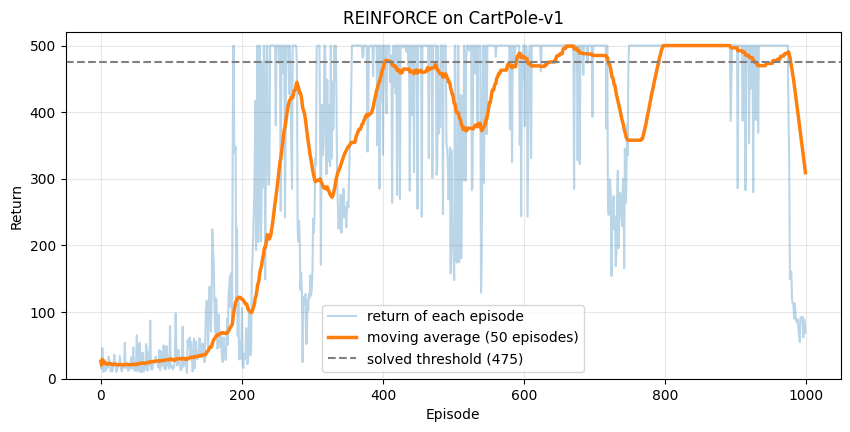

In [13]:
def moving_average(x, w=50):
    x = np.asarray(x, dtype=float)
    return np.array([x[max(0, i - w + 1): i + 1].mean() for i in range(len(x))])

plt.figure(figsize=(10, 4.5))
plt.plot(scores, alpha=0.3, label="return of each episode")
plt.plot(moving_average(scores), linewidth=2.5, label="moving average (50 episodes)")
plt.axhline(475, linestyle="--", color="gray", label="solved threshold (475)")
plt.xlabel("Episode"); plt.ylabel("Return"); plt.ylim(0, 520)
plt.title("REINFORCE on CartPole-v1")
plt.legend(); plt.grid(alpha=0.3); plt.show()

## Part 7 — Evaluate the trained policy (slide 18)
During training the agent **samples** its actions. After training we can compare two ways of acting:
- **stochastic:** keep sampling from $\pi_\theta(\cdot \mid s)$;
- **greedy:** always take the most probable action, $\arg\max_a \pi_\theta(a \mid s)$.

### TODO 10
Complete `evaluate`: play `n_episodes` episodes **without updating** the network and return the mean and standard deviation of the returns.

> 💡 Use `torch.no_grad()`; for greedy use `probs.argmax(dim=-1).item()`; for stochastic use `Categorical(probs).sample().item()`.

In [14]:
def evaluate(env, policy, n_episodes=20, greedy=True):
    returns = []
    for i in range(n_episodes):
        state, _ = env.reset(seed=1000 + i)
        total, done = 0.0, False
        while not done:
            # ---------------------------- TODO 10 ---------------------------
            with torch.no_grad():
                probs = policy(torch.as_tensor(state, dtype=torch.float32, device=device).unsqueeze(0))
            if greedy:
                action = probs.argmax(dim=-1).item()
            else:
                action = Categorical(probs).sample().item()
            # ----------------------------------------------------------------
            state, reward, terminated, truncated, _ = env.step(action)
            total += reward
            done = terminated or truncated
        returns.append(total)
    return float(np.mean(returns)), float(np.std(returns))

In [16]:
eval_env = gym.make("CartPole-v1")
for mode in (True, False):
    m, s = evaluate(eval_env, policy, n_episodes=200, greedy=mode)
    print(f"{'greedy    ' if mode else 'stochastic'} policy: {m:6.1f} ± {s:5.1f}")

random_returns = []
for k in range(20):                      # baseline: a random agent on the same seeds
    eval_env.reset(seed=1000 + k)
    total, done = 0.0, False
    while not done:
        _, r, term, trunc, _ = eval_env.step(eval_env.action_space.sample())
        total += r
        done = term or trunc
    random_returns.append(total)
print(f"random policy (baseline): {np.mean(random_returns):6.1f} ± {np.std(random_returns):5.1f}")

greedy     policy:   82.0 ±   5.5
stochastic policy:   78.0 ±  10.0
random policy (baseline):   22.6 ±  11.6


## Part 8 — Experiments and questions
### TODO 11 — Hyperparameter experiments
`run_experiment` trains a **fresh** agent with a given configuration. Fill the list `configs` with **at least three** configurations that differ from the default (lr = 1e-3, γ = 0.99, normalize = True) in **one** thing each, for example:
- a larger learning rate (e.g. `5e-3`),
- **no** return normalization,
- a smaller discount (e.g. `γ = 0.9`).

Run the cell, look at the plot and answer the questions below. (500 episodes per configuration, to keep it short.)

In [17]:
def run_experiment(lr=1e-3, gamma=0.99, normalize=True, n_episodes=500, seed=SEED):
    set_seed(seed)
    env = gym.make("CartPole-v1")
    env.reset(seed=seed)
    policy = PolicyNetwork(state_size, action_size).to(device)
    optimizer = optim.Adam(policy.parameters(), lr=lr)
    return reinforce(env, policy, optimizer, n_episodes=n_episodes, gamma=gamma,
                     normalize=normalize, print_every=n_episodes)


▶ default (lr=1e-3, γ=0.99, normalized)
Episode   500 | average return (last 100):  442.43

▶ large lr = 5e-3
Episode   500 | average return (last 100):  171.83

▶ no return normalization
Episode   500 | average return (last 100):   77.67

▶ short horizon γ = 0.9
Episode   500 | average return (last 100):  468.25


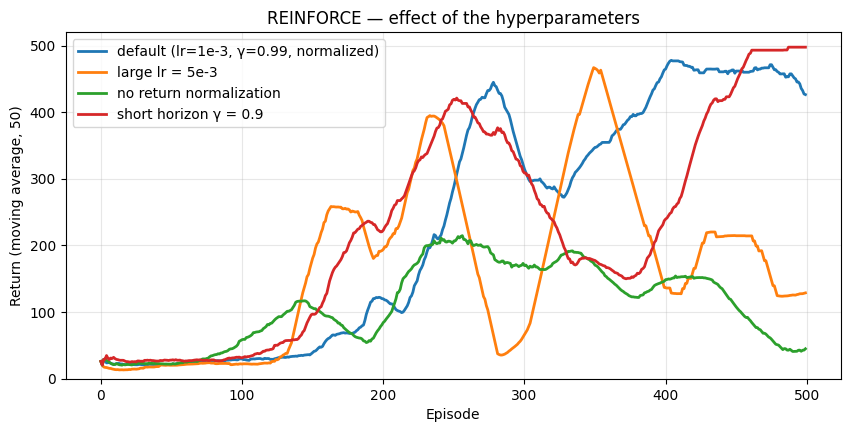

In [18]:
# ---------------------------- TODO 11 ---------------------------
configs = [
    {"label": "default (lr=1e-3, γ=0.99, normalized)", "lr": 1e-3, "gamma": 0.99, "normalize": True},
    {"label": "large lr = 5e-3",                         "lr": 5e-3, "gamma": 0.99, "normalize": True},
    {"label": "no return normalization",                 "lr": 1e-3, "gamma": 0.99, "normalize": False},
    {"label": "short horizon γ = 0.9",                   "lr": 1e-3, "gamma": 0.9,  "normalize": True},
]
# ----------------------------------------------------------------
assert len(configs) >= 4, "TODO 11: add at least three configurations to compare with the default"

results = {}
for cfg in configs:
    cfg = dict(cfg)
    label = cfg.pop("label")
    print(f"\n▶ {label}")
    results[label] = run_experiment(**cfg)

plt.figure(figsize=(10, 4.5))
for label, sc in results.items():
    plt.plot(moving_average(sc), linewidth=2, label=label)
plt.xlabel("Episode"); plt.ylabel("Return (moving average, 50)"); plt.ylim(0, 520)
plt.title("REINFORCE — effect of the hyperparameters"); plt.legend(); plt.grid(alpha=0.3); plt.show()

### Optional TODO 12 (bonus) — the γᵗ factor of slide 16
The update in the pseudocode is $\theta \leftarrow \theta + \alpha\,\gamma^t G_t\,\nabla_\theta \log \pi_\theta(a_t \mid s_t)$. Implement `reinforce_loss_textbook` with the extra factor $\gamma^t$, train with it (replace `reinforce_loss` temporarily or add a parameter) and compare the learning curve with the practical version.

In [ ]:
def reinforce_loss_textbook(log_probs, returns, gamma):
    # ---------------------------- TODO 12 (optional) ----------------
    discounts = gamma ** torch.arange(len(returns), dtype=torch.float32, device=device)
    return -(torch.stack(log_probs) * discounts * returns).sum()
    # ----------------------------------------------------------------

# Quick comparison: swap the loss used inside `reinforce`, train, then restore it.
_practical_loss = reinforce_loss
reinforce_loss = lambda lp, G: reinforce_loss_textbook(lp, G, gamma=0.99)
scores_textbook = run_experiment(lr=1e-3, gamma=0.99, normalize=True, n_episodes=500)
reinforce_loss = _practical_loss

plt.figure(figsize=(10, 4.5))
plt.plot(moving_average(results["default (lr=1e-3, γ=0.99, normalized)"]), linewidth=2, label="practical (no γᵗ)")
plt.plot(moving_average(scores_textbook), linewidth=2, label="textbook (with γᵗ)")
plt.xlabel("Episode"); plt.ylabel("Return (moving average, 50)"); plt.ylim(0, 520)
plt.legend(); plt.grid(alpha=0.3); plt.show()

### Questions
Answer briefly (2–4 sentences each) in the cell below.

**Q1.** Why does `reinforce_loss` have a **minus** sign, if REINFORCE performs gradient *ascent*?

**Q2.** REINFORCE must wait until the **end of the episode** before updating. Why? How is this different from SARSA or Q-learning?

**Q3.** Look at the learning curve of Part 6. Why is it so noisy, and why can performance **drop** after reaching 500? (slide 21)

**Q4.** Where does **exploration** come from in REINFORCE? Why don't we need ε-greedy as in DQN? (slide 18)

**Q5.** What happened with the larger learning rate and without normalization in TODO 11? Explain using the update rule.

**Q6.** Could we store old episodes in a **replay buffer** and reuse them, as in DQN? Why or why not?

### 🧑‍🏫 Answer key

- **Q1.** PyTorch optimizers implement gradient *descent* (they minimize). Minimizing $L = -\sum_t \log\pi_\theta(a_t|s_t)\,G_t$ is the same as maximizing $\sum_t \log\pi_\theta(a_t|s_t)\,G_t$, whose gradient is the policy-gradient estimate $\hat g$. So `loss.backward()` + `optimizer.step()` performs $\theta \leftarrow \theta + \alpha \hat g$, i.e. gradient ascent on $J(\theta)$.

- **Q2.** $G_t$ is the sum of **all** future rewards until the episode ends; it is only known when the episode finishes. REINFORCE uses this real, sampled return (Monte Carlo) instead of an estimate. SARSA and Q-learning are **TD** methods: they bootstrap with $r_t + \gamma Q(s_{t+1}, \cdot)$ and can update after every step, at the cost of bias from the estimate.

- **Q3.** Each update uses the return of **a single sampled episode**. Returns vary a lot because of random actions and random initial states, so the gradient estimate has high variance: luck is rewarded like skill, and a bad action inside a good episode is reinforced too. A large noisy step can push the policy away from a good region (no trust region), which explains the drops; the policy then has to recover. Baselines/critics (Actor–Critic) and PPO's clipping address this.

- **Q4.** From the stochastic policy itself: actions are **sampled** from $\pi_\theta(\cdot|s)$, so every action keeps a non-zero probability. Early in training the distribution is close to uniform (lots of exploration); as learning progresses it concentrates on good actions (exploitation). DQN needs ε-greedy because its greedy argmax policy is deterministic.

- **Q5.** *Typical observation (exact curves depend on the seed):* with lr = 5e-3 the agent may learn faster at first but often **collapses** to a near-deterministic bad policy (returns stuck near 9–10) or oscillates strongly — the steps $\alpha\,\hat g$ are too large for such a noisy estimate. Without normalization all $G_t$ in CartPole are **positive** (≈ up to 100 with γ = 0.99), so every action taken is pushed up, and the scale of the gradient grows with episode length; learning is slower and less stable. Normalizing centers the returns (a simple baseline): actions better than the episode average go up, worse ones go down. With γ = 0.9 the effective horizon is ~10 steps; it still learns on CartPole, but credit assignment is shorter-sighted.

- **Q6.** Not directly. REINFORCE is **on-policy**: the gradient $\mathbb{E}_{\pi_\theta}[\cdot]$ is an expectation over trajectories generated by the **current** policy. Episodes collected with old parameters come from a different distribution, so reusing them gives a biased gradient. It would require importance-sampling corrections ($\pi_\theta / \pi_{\theta_{old}}$), which is the idea behind off-policy policy gradients and, with clipping, PPO.

**TODO 12 (bonus).** With the $\gamma^t$ factor, late time steps get almost no weight ($0.99^{300} \approx 0.05$), so the agent learns little from the later part of long episodes. On CartPole it usually learns **more slowly** than the practical version. It is the theoretically exact gradient of the discounted objective from the start state; implementations drop it because it in practice down-weights useful data.

---
### References
- M. Hu, *The Art of Reinforcement Learning*, Apress, 2023 — Algorithm 21 (REINFORCE) and the policy-network figure.
- Hugging Face Deep RL Course, Unit 4: *Policy Gradient with PyTorch* — https://huggingface.co/learn/deep-rl-course/unit4/
- Lecture slides: *Policy Gradient & REINFORCE* (UC2 2.4), slides 16–21.